# Stage 3 — K-means Segmentation

Segments campaign 18's active households (from `data/processed/model_table.parquet`)
into behavioral clusters using only pre-period shopping behavior — no targeting,
redemption, or outcome information. The goal is a set of interpretable, business-nameable
segments an offers team could act on, plus a look at how campaign 18 targeting and
redemption rates vary across them (targeting/redemption are used only to *describe* the
segments after the fact, never as clustering inputs).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
sns.set_theme(style="white")
SEGMENT_PALETTE = sns.color_palette("colorblind", n_colors=8)


## 1. Load campaign 18 rows and select behavioral features

Features are restricted to pre-period shopping behavior: RFM + basket shape, spend
trend, discount/coupon behavior, past redemptions, and department spend shares.
`treated`, `redeemed`, and the outcome columns are excluded entirely — the segmentation
must not "know" who was targeted or what they did with a coupon, since it will be used
*to describe* targeting and redemption patterns afterward.


In [2]:
model_table = pd.read_parquet("../data/processed/model_table.parquet")
campaign_18 = model_table[model_table["campaign_id"] == 18].reset_index(drop=True)

BEHAVIORAL_COLS = [
    "recency_days",
    "frequency_baskets",
    "monetary_spend",
    "avg_basket_value",
    "items_per_basket",
    "spend_trend_ratio",
    "retail_disc_share",
    "coupon_disc_total",
    "past_redemptions_count",
    "spend_share_grocery",
    "spend_share_drug_gm",
    "spend_share_fuel",
    "spend_share_produce",
    "spend_share_meat",
    "spend_share_meat_pckgd",
]

print(f"Campaign 18 active households: {len(campaign_18):,}")
X = campaign_18[BEHAVIORAL_COLS].copy()
X.describe().T


Campaign 18 active households: 2,344


,count,mean,std,min,25%,50%,75%,max
recency_days,2344.0,12.791382,19.855163,0.00,1.000000,5.000000,15.000000,111.000000
frequency_baskets,2344.0,20.449659,23.206969,1.00,6.000000,14.000000,27.000000,252.000000
monetary_spend,2344.0,590.495725,647.886474,0.59,138.965000,384.155000,811.305000,8166.260000
avg_basket_value,2344.0,31.696016,23.598045,0.59,15.835250,25.700667,40.656833,234.180000
items_per_basket,2344.0,792.105936,1568.186008,1.00,8.677451,19.258333,927.537081,18071.000000
spend_trend_ratio,2344.0,1.360080,1.993754,0.00,0.410165,0.921161,1.424270,14.681122
retail_disc_share,2344.0,0.180379,0.107227,0.00,0.116868,0.162495,0.219279,1.000000
coupon_disc_total,2344.0,3.393434,10.496065,0.00,0.000000,0.000000,2.500000,213.000000
past_redemptions_count,2344.0,0.552048,1.928917,0.00,0.000000,0.000000,0.000000,27.000000
spend_share_grocery,2344.0,0.512224,0.171833,0.00,0.411860,0.521056,0.618040,1.000000


## 2. Log-transform skewed features, then scale

Skew is measured on each feature; anything with `|skew| > 1` gets a `log1p` transform
before scaling (all these features are non-negative, so `log1p` is safe). This compresses
the long right tails from heavy spenders / frequent redeemers so they don't dominate the
Euclidean distances K-means relies on. Every feature — log-transformed or not — then goes
through the same `StandardScaler` so no single feature's units (dollars vs. a 0–1 share)
dominate just because of scale.


In [3]:
skew = X.skew().sort_values(ascending=False)
skewed_cols = skew[skew.abs() > 1.0].index.tolist()

print("Skew per feature:")
print(skew.round(2))
print()
print(f"Log1p applied to ({len(skewed_cols)} of {len(BEHAVIORAL_COLS)} features):", skewed_cols)

X_log = X.copy()
X_log[skewed_cols] = np.log1p(X_log[skewed_cols])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)


Skew per feature:
coupon_disc_total         8.93
past_redemptions_count    5.33
spend_trend_ratio         4.01
frequency_baskets         3.75
spend_share_produce       3.64
spend_share_fuel          3.33
items_per_basket          3.17
spend_share_meat          2.83
spend_share_meat_pckgd    2.77
recency_days              2.52
spend_share_drug_gm       2.52
monetary_spend            2.49
retail_disc_share         2.34
avg_basket_value          2.26
spend_share_grocery      -0.18
dtype: float64

Log1p applied to (14 of 15 features): ['coupon_disc_total', 'past_redemptions_count', 'spend_trend_ratio', 'frequency_baskets', 'spend_share_produce', 'spend_share_fuel', 'items_per_basket', 'spend_share_meat', 'spend_share_meat_pckgd', 'recency_days', 'spend_share_drug_gm', 'monetary_spend', 'retail_disc_share', 'avg_basket_value']


## 3. Fit K-means for k = 2..10 — elbow and silhouette


In [4]:
k_range = range(2, 11)
inertias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

metrics = pd.DataFrame({"k": list(k_range), "inertia": inertias, "silhouette": silhouettes})
metrics


,k,inertia,silhouette
0,2,29595.536792,0.148837
1,3,27160.026207,0.119697
2,4,24970.473177,0.132520
3,5,23395.009616,0.133122
4,6,22209.864722,0.126952
5,7,21148.299073,0.118002
6,8,20108.178049,0.127834
7,9,19231.490564,0.134248
8,10,18444.095523,0.136069


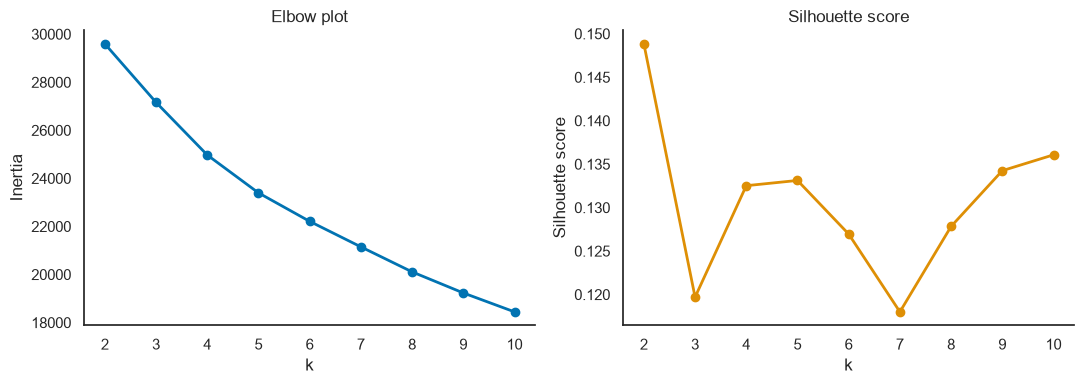

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(metrics["k"], metrics["inertia"], marker="o", color=SEGMENT_PALETTE[0], linewidth=2)
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow plot")
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].plot(metrics["k"], metrics["silhouette"], marker="o", color=SEGMENT_PALETTE[1], linewidth=2)
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette score")
axes[1].spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()


## 4. Choice of k

Silhouette scores are modest across the board (0.12–0.15) — expected for continuous
retail behavior features that form a spectrum rather than naturally separated clusters.
The technical-best silhouette is at k=2, but two clusters ("light" vs. "heavy" shoppers)
would collapse away most of the behavioral variety that actually distinguishes who a
coupon program might treat differently, and silhouette alone would also happily walk up
to k=10, which isn't interpretable for a business audience.

Looking at the elbow instead: the inertia drop between successive k slows from ~8%
(k=2→3, 3→4) to ~6% (4→5) and then flattens into a shallow ~5%/step tail from k=5 onward
— the knee sits around **k=4–5**. Silhouette also recovers from its k=3 dip by k=4–5
before dipping again at 6–7. Balancing both metrics against how many distinct,
nameable stories an offers team can act on, **k=5** is the choice: it sits right at the
elbow's knee, has one of the better silhouette scores in the 3–8 range, and produces
segments with clearly distinct recency/frequency/spend/redemption profiles (see below).


In [6]:
K_FINAL = 5
kmeans_final = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10)
campaign_18["segment"] = kmeans_final.fit_predict(X_scaled)

campaign_18["segment"].value_counts().sort_index().rename("size")


segment
0    399
1    857
2    266
3    318
4    504
Name: size, dtype: int64

## 5. Segment profiles (original units) and business names

Mean of each behavioral feature by segment, in its original units (dollars, days,
counts, shares) — not the scaled/log values used for clustering.


In [7]:
profile = campaign_18.groupby("segment")[BEHAVIORAL_COLS].mean().round(2)
profile.insert(0, "size", campaign_18["segment"].value_counts().sort_index())
profile


,size,recency_days,frequency_baskets,monetary_spend,avg_basket_value,items_per_basket,spend_trend_ratio,retail_disc_share,coupon_disc_total,past_redemptions_count,spend_share_grocery,spend_share_drug_gm,spend_share_fuel,spend_share_produce,spend_share_meat,spend_share_meat_pckgd
segment,,,,,,,,,,,,,,,,
0,399,33.06,5.74,125.26,26.72,44.93,0.69,0.27,0.62,0.03,0.63,0.07,0.00,0.05,0.09,0.08
1,857,4.83,20.48,588.70,35.42,121.10,2.04,0.18,1.67,0.06,0.57,0.11,0.01,0.07,0.08,0.06
2,266,2.81,39.32,1417.84,43.59,1613.65,1.02,0.18,18.58,4.46,0.50,0.13,0.09,0.07,0.06,0.05
3,318,24.30,7.03,115.49,19.06,113.31,1.17,0.12,0.36,0.01,0.37,0.29,0.00,0.12,0.02,0.02
4,504,8.30,30.55,824.92,31.00,2519.29,1.03,0.14,2.42,0.08,0.41,0.11,0.21,0.06,0.05,0.04


In [8]:
SEGMENT_NAMES = {
    0: "Lapsing, low engagement",
    1: "Rising spenders",
    2: "Loyal big-basket / coupon power users",
    3: "Light, occasional shoppers",
    4: "Frequent fuel & grocery shoppers",
}
campaign_18["segment_name"] = campaign_18["segment"].map(SEGMENT_NAMES)

named_profile = profile.rename(index=SEGMENT_NAMES)
named_profile


,size,recency_days,frequency_baskets,monetary_spend,avg_basket_value,items_per_basket,spend_trend_ratio,retail_disc_share,coupon_disc_total,past_redemptions_count,spend_share_grocery,spend_share_drug_gm,spend_share_fuel,spend_share_produce,spend_share_meat,spend_share_meat_pckgd
segment,,,,,,,,,,,,,,,,
"Lapsing, low engagement",399,33.06,5.74,125.26,26.72,44.93,0.69,0.27,0.62,0.03,0.63,0.07,0.00,0.05,0.09,0.08
Rising spenders,857,4.83,20.48,588.70,35.42,121.10,2.04,0.18,1.67,0.06,0.57,0.11,0.01,0.07,0.08,0.06
Loyal big-basket / coupon power users,266,2.81,39.32,1417.84,43.59,1613.65,1.02,0.18,18.58,4.46,0.50,0.13,0.09,0.07,0.06,0.05
"Light, occasional shoppers",318,24.30,7.03,115.49,19.06,113.31,1.17,0.12,0.36,0.01,0.37,0.29,0.00,0.12,0.02,0.02
Frequent fuel & grocery shoppers,504,8.30,30.55,824.92,31.00,2519.29,1.03,0.14,2.42,0.08,0.41,0.11,0.21,0.06,0.05,0.04


### 5a. `spend_trend_ratio` — mean vs. median by segment

The mean alone can be misleading for a feature this skewed; the median shows where the
typical household in each segment actually sits.

In [9]:
trend_mean_median = (
    campaign_18.groupby("segment_name")["spend_trend_ratio"]
    .agg(["mean", "median"])
    .round(3)
    .loc[list(SEGMENT_NAMES.values())]
)
trend_mean_median


,mean,median
segment_name,,
"Lapsing, low engagement",0.692,0.106
Rising spenders,2.042,1.200
Loyal big-basket / coupon power users,1.025,0.988
"Light, occasional shoppers",1.170,0.549
Frequent fuel & grocery shoppers,1.027,0.823


## 6. Segment profile heatmap

Each feature is z-scored *across segments* (so every row uses a comparable color scale)
and shown on a diverging red–blue scale centered at 0; cells are annotated with the
original-unit means from the table above so the heatmap is readable both by color
(relative to other segments) and by the actual number.


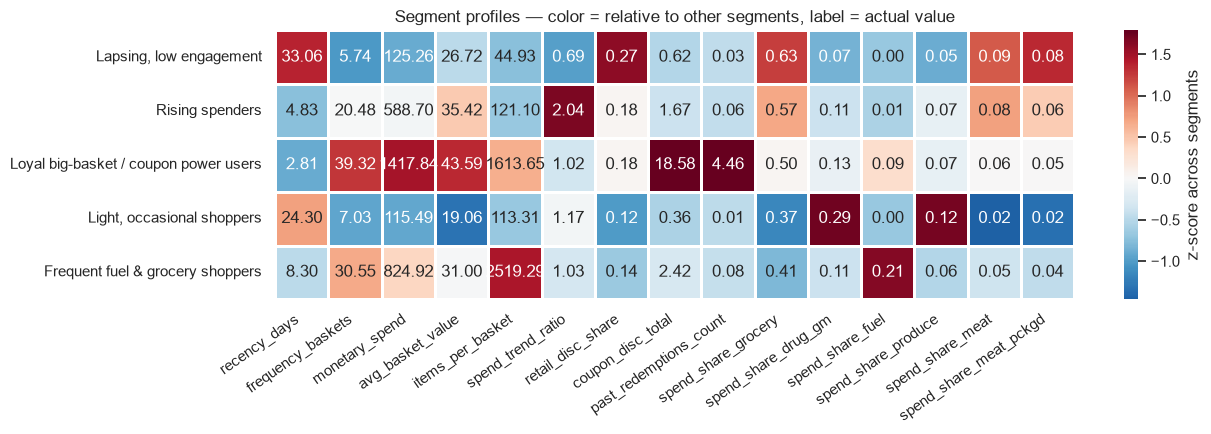

In [10]:
z_profile = profile[BEHAVIORAL_COLS].apply(lambda col: (col - col.mean()) / col.std(), axis=0)
z_profile.index = [SEGMENT_NAMES[i] for i in z_profile.index]
annot_values = profile[BEHAVIORAL_COLS].values
annot_values_display = profile.rename(index=SEGMENT_NAMES)[BEHAVIORAL_COLS]

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(
    z_profile,
    annot=annot_values_display.values,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=2,
    linecolor="white",
    cbar_kws={"label": "z-score across segments"},
    ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Segment profiles — color = relative to other segments, label = actual value")
plt.xticks(rotation=35, ha="right")
fig.tight_layout()
plt.show()


## 6a. How much does each feature drive the clustering?

The heatmap above is in original units and z-scored *per feature*, which is good for
reading actual values but doesn't say which features K-means actually used most to tell
segments apart. For that, look directly at the five cluster centroids in the **scaled
(log1p + StandardScaler) units K-means optimized over** — the space is already unit-free,
so the range a feature's centroids span *is* a fair measure of how much that feature
contributes to separating segments.

In [11]:
centroids = pd.DataFrame(kmeans_final.cluster_centers_, columns=BEHAVIORAL_COLS)
centroid_spread = pd.DataFrame(
    {
        "range_across_segments": centroids.max() - centroids.min(),
        "std_across_segments": centroids.std(),
    }
).sort_values("range_across_segments", ascending=False)
centroid_spread.round(3)


,range_across_segments,std_across_segments
past_redemptions_count,2.752,1.214
coupon_disc_total,2.322,0.946
items_per_basket,2.181,0.966
monetary_spend,2.122,0.943
frequency_baskets,1.922,0.847
spend_share_fuel,1.827,0.793
recency_days,1.755,0.746
spend_share_drug_gm,1.623,0.615
spend_share_grocery,1.500,0.624
retail_disc_share,1.485,0.560


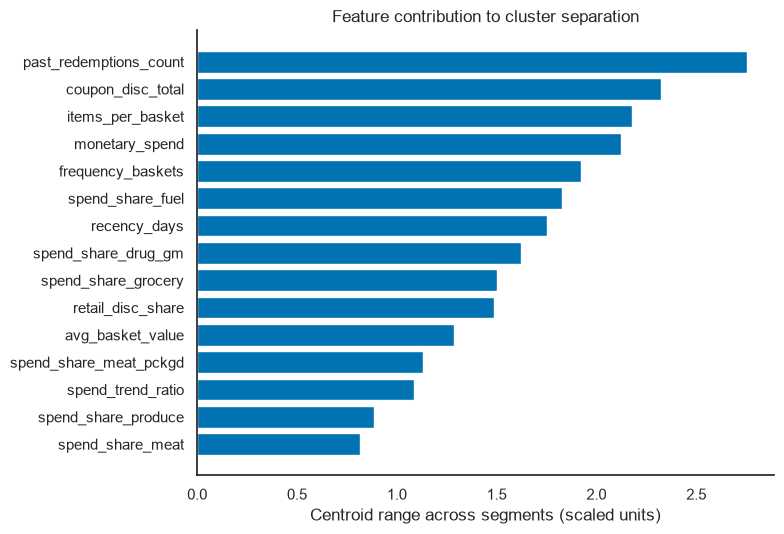

In [12]:
fig, ax = plt.subplots(figsize=(8, 5.5))
order = centroid_spread.index
ax.barh(order, centroid_spread.loc[order, "range_across_segments"], color=SEGMENT_PALETTE[0])
ax.invert_yaxis()
ax.set_xlabel("Centroid range across segments (scaled units)")
ax.set_title("Feature contribution to cluster separation")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


**`spend_trend_ratio` is not the dominant driver.** It ranks 13th of 15 features by
centroid range — the clustering is actually driven far more by `past_redemptions_count`,
`coupon_disc_total`, `items_per_basket`, `monetary_spend`, and `frequency_baskets` (the
top five), with `recency_days` and `spend_share_fuel` also ahead of it. Rising Spenders
is separated mainly by its distinctly high `frequency_baskets`/`monetary_spend` combined
with low `recency_days`, not by `spend_trend_ratio` alone — the trend ratio is a real but
secondary signal, not the thing carrying that cluster.

### 6b. Stability check: re-run without log-transforming `spend_trend_ratio`

The driver check above already shows `spend_trend_ratio` isn't what's carrying Rising
Spenders, but as a direct robustness check: `spend_trend_ratio`'s skew (4.01) means it
was already `log1p`-transformed in the main pipeline (section 2). Here it's left in its
raw (untransformed) units instead — everything else identical — and the resulting
clusters are compared to the baseline via a contingency table and the Adjusted Rand Index
(1.0 = identical partitions, 0.0 = random agreement).

In [13]:
from sklearn.metrics import adjusted_rand_score

log_cols_no_trend = [c for c in skewed_cols if c != "spend_trend_ratio"]
X_log_alt = X.copy()
X_log_alt[log_cols_no_trend] = np.log1p(X_log_alt[log_cols_no_trend])
X_scaled_alt = StandardScaler().fit_transform(X_log_alt)

kmeans_alt = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10)
segment_alt = kmeans_alt.fit_predict(X_scaled_alt)

ari = adjusted_rand_score(campaign_18["segment"], segment_alt)
print(f"Adjusted Rand Index vs. baseline (log1p trend) clustering: {ari:.3f}")

contingency = pd.crosstab(
    campaign_18["segment"].map(SEGMENT_NAMES).rename("baseline_segment"),
    pd.Series(segment_alt, name="raw_trend_segment"),
).loc[list(SEGMENT_NAMES.values())]
contingency


Adjusted Rand Index vs. baseline (log1p trend) clustering: 0.588


raw_trend_segment,0,1,2,3,4
baseline_segment,,,,,
"Lapsing, low engagement",389,0,3,0,7
Rising spenders,170,1,671,0,15
Loyal big-basket / coupon power users,0,247,18,1,0
"Light, occasional shoppers",6,0,2,2,308
Frequent fuel & grocery shoppers,1,4,176,322,1


**Segments are reasonably stable (ARI ≈ 0.59, moderate-to-strong agreement).** Three of
the five — Lapsing/low engagement, Loyal big-basket/coupon power users, and Light/
occasional shoppers — stay 93–97% intact under the alternative transform. Rising Spenders
mostly survives too (about 78% of it lands in one corresponding cluster on the rerun);
the main movement is some reshuffling between Rising Spenders and Frequent fuel & grocery
shoppers, which were already the two segments closest together in the driver analysis
above (both mid-range on recency/frequency/spend). This confirms the earlier finding:
Rising Spenders is not an artifact of how `spend_trend_ratio` was transformed — the
segment is anchored by frequency/monetary/recency, and the log-transform choice only
affects the boundary between two already-similar segments, not the overall segmentation
story.

## 7. PCA 2D scatter, colored by segment


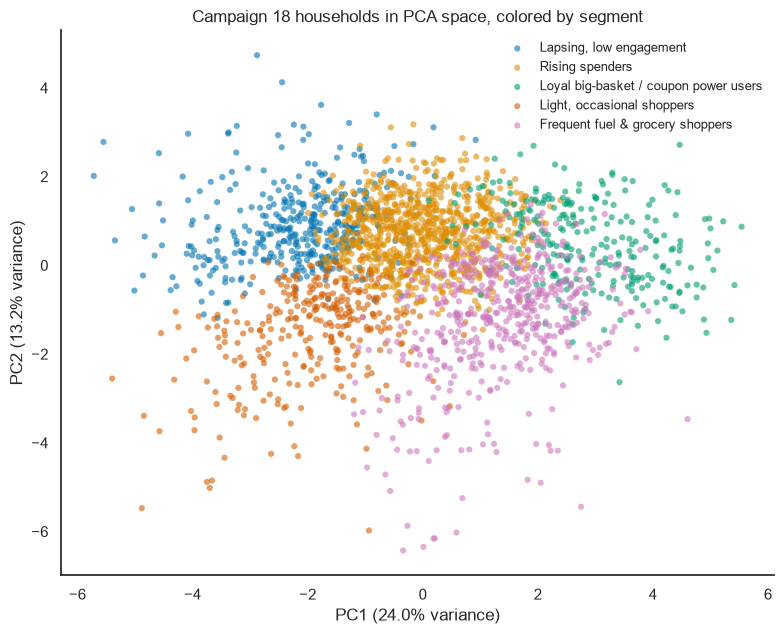

In [14]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)
campaign_18["pca_1"] = coords[:, 0]
campaign_18["pca_2"] = coords[:, 1]

explained = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(8, 6.5))
for i, (segment, name) in enumerate(SEGMENT_NAMES.items()):
    subset = campaign_18[campaign_18["segment"] == segment]
    ax.scatter(
        subset["pca_1"], subset["pca_2"],
        s=20, alpha=0.6, color=SEGMENT_PALETTE[i], label=name, edgecolor="none",
    )

ax.set_xlabel(f"PC1 ({explained[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({explained[1]:.1%} variance)")
ax.set_title("Campaign 18 households in PCA space, colored by segment")
ax.legend(loc="best", fontsize=9, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


## 8. Segments vs. campaign 18 targeting, redemption, and overlap

One table per segment: total households, treated/control counts, % targeted, and
redemption rate among treated. Computed by re-reading `model_table.parquet` and
`segments.parquet` directly (not reusing the in-notebook `campaign_18` frame) as an
independent check that the saved files agree with what's shown above.

In [15]:
model_table_check = pd.read_parquet("../data/processed/model_table.parquet")
segments_check = pd.read_parquet("../data/processed/segments.parquet")

campaign_18_check = model_table_check.loc[
    model_table_check["campaign_id"] == 18, ["household_id", "treated", "redeemed"]
].merge(segments_check[["household_id", "segment_name"]], on="household_id", how="inner")

assert len(campaign_18_check) == len(campaign_18), "Row count mismatch vs. in-notebook campaign_18"


def _segment_summary(g):
    treated = g["treated"] == 1
    return pd.Series(
        {
            "total_households": len(g),
            "treated_count": int(treated.sum()),
            "control_count": int((~treated).sum()),
            "pct_targeted": round(100 * treated.mean(), 1),
            "redemption_rate_among_treated": round(g.loc[treated, "redeemed"].mean(), 4),
        }
    )


segment_vs_campaign = (
    campaign_18_check.groupby("segment_name")
    .apply(_segment_summary, include_groups=False)
    .loc[list(SEGMENT_NAMES.values())]
)
segment_vs_campaign


,total_households,treated_count,control_count,pct_targeted,redemption_rate_among_treated
segment_name,,,,,
"Lapsing, low engagement",399.0,60.0,339.0,15.0,0.1000
Rising spenders,857.0,455.0,402.0,53.1,0.0747
Loyal big-basket / coupon power users,266.0,241.0,25.0,90.6,0.5519
"Light, occasional shoppers",318.0,56.0,262.0,17.6,0.0357
Frequent fuel & grocery shoppers,504.0,317.0,187.0,62.9,0.1230


**Overlap is uneven in both directions, not just for one segment:**

- **Loyal big-basket / coupon power users**: 241 treated vs. only **25 control** — almost
  no control group, consistent with 91% targeting.
- **Lapsing, low engagement**: 339 control vs. only **60 treated** — the earlier "15%
  targeted" figure is exactly this: few of this segment are ever mailed, so there's plenty
  of control data but very little treated data.
- **Light, occasional shoppers**: 262 control vs. only **56 treated** — same shape as
  Lapsing (17.6% targeted), also short on treated data.
- **Rising spenders** (402 control / 455 treated) and **Frequent fuel & grocery shoppers**
  (187 control / 317 treated) are the only two segments with reasonably sized groups on
  *both* sides, so they're the segments where a within-segment propensity/uplift estimate
  can actually be trusted. For Loyal, Lapsing, and Light, whichever side is thin will drive
  wide confidence intervals on any within-segment effect estimate.

(An earlier version of this notebook said "every other segment has at least ~190
households on each side" — that was wrong: it was eyeballing the control counts only and
didn't check the treated counts, which are the thin side for Lapsing and Light.)

## 9. Save segment labels

In [16]:
segments_out = campaign_18[["household_id", "segment", "segment_name"]].copy()
segments_out.to_parquet("../data/processed/segments.parquet", index=False)
segments_out.head()


,household_id,segment,segment_name
0,1,2,Loyal big-basket / coupon power users
1,2,1,Rising spenders
2,3,0,"Lapsing, low engagement"
3,4,0,"Lapsing, low engagement"
4,5,3,"Light, occasional shoppers"


## 10. What each segment means for an offers team

| Segment | Size | Behavior | Targeting & redemption |
|---|---|---|---|
| **Loyal big-basket / coupon power users** | 266 (11%) | Shops almost every week (39 trips/16 weeks), highest spend ($1,418), by far the most past coupon redemptions (4.5) and coupon discount dollars ($18.58) | **91% already targeted**, and a striking **55% redemption rate** among targeted |
| **Frequent fuel & grocery shoppers** | 504 (22%) | Frequent (30.5 trips), high spend ($825), distinctly higher fuel spend share (21% vs. 0–9% elsewhere) | 63% targeted, 12% redemption |
| **Rising spenders** | 857 (37%, largest segment) | Recent (4.8 days), moderate spend ($589), and the **highest spend-trend ratio** (mean 2.04, median 1.20) — spend in the most recent 4 weeks is running at roughly double the average weekly pace of the prior 12 weeks | 53% targeted, only 7.5% redemption |
| **Lapsing, low engagement** | 399 (17%) | Stale (33 days since last purchase), infrequent (5.7 trips), low spend ($125), and the only segment with a *declining* spend trend (mean 0.69, median 0.11 — most of this group's recent spend has nearly stopped) | Only 15% targeted, 10% redemption (on a small targeted base) |
| **Light, occasional shoppers** | 318 (14%) | Low frequency (7 trips), lowest spend ($115) and smallest baskets ($19), skew toward drug/GM rather than grocery | 18% targeted, lowest redemption (3.6%) |

**Reading for an offers team:**

- **Loyal big-basket / coupon power users are already saturated.** 91% are targeted and
  they redeem at 10x the rate of most other segments — the retailer has clearly identified
  and is already heavily mailing this group. There's little room left to grow volume here;
  the open question for the uplift stage is whether their high *redemption* rate reflects
  coupons actually changing behavior, or whether they would have bought the couponed
  products anyway (free-riding) — a segment exactly worth checking against the T-learner's
  uplift estimate rather than redemption rate alone. It also has almost no control group
  (25 households, section 8), so any within-segment uplift estimate here will be noisy
  regardless of method.
- **Rising spenders are the most interesting growth opportunity.** It's the largest segment
  (37% of active households), recent spend is running well above its own prior-12-week
  pace, yet only about half are targeted and redemption is low (7.5%). It's also one of only
  two segments with solid treated *and* control counts (455 / 402, section 8), so it's a
  segment where the uplift model's estimate can actually be trusted. If it shows real
  incremental lift, this is where expanding targeting would pay off — a household whose
  spend is already climbing may be primed to respond to a nudge, and there's clear
  targeting headroom.
- **Frequent fuel & grocery shoppers** are a solid, moderately-targeted segment with
  moderate redemption and the other segment with good treated/control balance (317 / 187)
  — a reasonable "keep doing what's working" group, perhaps worth testing fuel-linked
  offers given their distinct spend share.
- **Lapsing and light/occasional shoppers are low-priority for coupon spend as currently
  targeted** — low targeting, low redemption, and (for the lapsing group) spend that's
  already trending down. Both also have thin *treated* groups (60 and 56 households,
  section 8) — the mirror image of Loyal's thin control group — so any within-segment
  uplift read for these two will likewise be noisy, just because there isn't much treated
  data rather than too little control. Coupons aimed at pure win-back for the lapsing
  segment would need a different lens (e.g. a win-back campaign evaluated on its own terms)
  rather than more of the current Type-A-style offer, since the current approach clearly
  isn't reaching or converting them.

This segmentation is intentionally built without using `treated`/`redeemed`/outcome
data, so it gives the offers team a behavior-only lens to sit alongside the propensity and
uplift models — e.g. checking whether the uplift model's recommended households cluster
in "rising spenders" (opportunity, good overlap) vs. "loyal power users" (likely
saturated, high redemption but thin control group) vs. "lapsing"/"light" (thin treated
group either way).